# LTTB Demo for a Double-Spend Probability Graph

This notebook:

- generates dummy probability data
- applies **Largest-Triangle-Three-Buckets (LTTB)** downsampling
- plots the raw and sampled series

It's a simple starting point before adding websockets, APIs, or a frontend.


In [1]:
import math
import random
from typing import List, Tuple
import matplotlib.pyplot as plt


## 1) Generate dummy time-series data

We'll simulate a noisy probability curve with occasional spikes.


In [2]:
Point = Tuple[float, float]  # (x, y)

def generate_dummy_data(num_points: int = 5000) -> List[Point]:
    data: List[Point] = []

    for i in range(num_points):
        base = 0.02 + 0.01 * math.sin(i / 80)
        noise = random.uniform(-0.003, 0.003)

        spike = 0.0
        if i % 700 == 0 and i != 0:
            spike = random.uniform(0.03, 0.08)

        y = max(0.0, min(1.0, base + noise + spike))
        data.append((i, y))

    return data

raw_data = generate_dummy_data(5000)
len(raw_data), raw_data[:5]


(5000,
 [(0, 0.01813929697098452),
  (1, 0.022156651000777332),
  (2, 0.019719124156414428),
  (3, 0.018699757536082315),
  (4, 0.02348328714678447)])

## 2) Implement LTTB

This picks a smaller set of points while trying to preserve the overall visual shape.


In [3]:
def lttb(data: List[Point], threshold: int) -> List[Point]:
    """
    Largest-Triangle-Three-Buckets downsampling.
    data must be sorted by x.
    threshold is the number of points to keep.
    """
    if threshold >= len(data) or threshold == 0:
        return data[:]

    if threshold < 3:
        raise ValueError("threshold must be at least 3")

    sampled: List[Point] = [data[0]]
    bucket_size = (len(data) - 2) / (threshold - 2)

    a = 0  # index of the previously selected point

    for i in range(threshold - 2):
        # Calculate average of next bucket
        avg_range_start = int((i + 1) * bucket_size) + 1
        avg_range_end = int((i + 2) * bucket_size) + 1
        avg_range_end = min(avg_range_end, len(data))

        avg_x = 0.0
        avg_y = 0.0
        avg_range_length = max(1, avg_range_end - avg_range_start)

        for j in range(avg_range_start, avg_range_end):
            avg_x += data[j][0]
            avg_y += data[j][1]

        avg_x /= avg_range_length
        avg_y /= avg_range_length

        # Current bucket range
        range_offs = int(i * bucket_size) + 1
        range_to = int((i + 1) * bucket_size) + 1
        range_to = min(range_to, len(data) - 1)

        ax, ay = data[a]

        max_area = -1.0
        next_a = range_offs

        for j in range(range_offs, range_to):
            px, py = data[j]

            area = abs(
                (ax - avg_x) * (py - ay) -
                (ax - px) * (avg_y - ay)
            ) * 0.5

            if area > max_area:
                max_area = area
                next_a = j

        sampled.append(data[next_a])
        a = next_a

    sampled.append(data[-1])
    return sampled


## 3) Downsample the series

A common trick is to keep around as many points as the chart can actually show.
For now we'll just pick a fixed threshold.


In [4]:
threshold = 300
sampled_data = lttb(raw_data, threshold)

print(f"Raw points: {len(raw_data)}")
print(f"Sampled points: {len(sampled_data)}")


Raw points: 5000
Sampled points: 300


## 4) Plot raw vs sampled


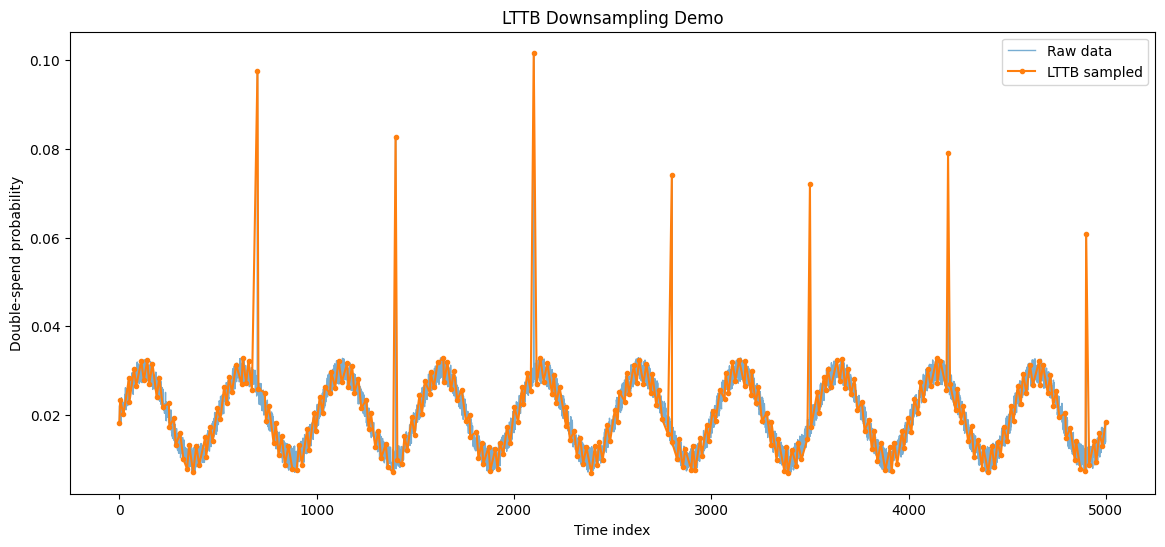

In [10]:
raw_x = [p[0] for p in raw_data]
raw_y = [p[1] for p in raw_data]

sampled_x = [p[0] for p in sampled_data]
sampled_y = [p[1] for p in sampled_data]

plt.figure(figsize=(14, 6))
plt.plot(raw_x, raw_y, linewidth=1, alpha=0.6, label='Raw data')
plt.plot(sampled_x, sampled_y, marker='o', linestyle='-', linewidth=1.5, markersize=3, label='LTTB sampled')
plt.xlabel('Time index')
plt.ylabel('Double-spend probability')
plt.title('LTTB Downsampling Demo')
plt.legend()
plt.show()


## 5) Helper function for screen-width style sampling

Later, in an API or frontend, you'd usually sample based on chart width.


In [8]:
def downsample_for_width(points: List[Point], pixel_width: int) -> List[Point]:
    # Keep about 1-2 points per pixel, with a minimum floor
    threshold = max(100, min(len(points), pixel_width))
    return lttb(points, threshold)

sampled_800 = downsample_for_width(raw_data, 800)
print(f"Points for ~800px chart: {len(sampled_800)}")


Points for ~800px chart: 800


## 6) Next step ideas

Once this notebook looks good, the next upgrades are:

- swap dummy values for real backend output
- move LTTB into your API layer
- return only sampled points to the frontend
- add zoom/pan and resample by viewport width
- later add websocket updates for new points
